# Injecting a $T$ gate into the Steane code

This notebook takes one protocol from a circuit of ordinary gates to the statement *"this implements a logical $T$"*, and checks every step. It is also a tour of what the library does, so it starts from scratch: no quantum error correction is assumed.

## 0. The problem, in plain terms

A quantum computer's qubits are fragile, so we do not compute with them directly. Instead a **logical qubit** is spread over many **physical qubits** in a way that lets us detect disturbances — that is a *code*. This notebook uses the **Steane code**, which stores one logical qubit in seven physical ones.

Spreading the information out has a price: you can no longer act on the logical qubit by touching it directly, and only some gates survive the encoding easily. A gate is **transversal** when applying the *same* one-qubit gate to each of the seven physical qubits performs that gate on the logical qubit — cheap, and it never spreads a fault from one qubit to another. For the Steane code the gates $H$, $S$ and CNOT are transversal. The $T$ gate is not, and no code makes every gate transversal.

So $T$ is done differently: prepare a special state — a **magic state** $|A\rangle = T|+\rangle$ — and consume it with gates that *are* transversal. That trick is called **injection**, and it is what this notebook builds and verifies.

## 1. Setup

One cell of imports, and the description of the code: three *stabilizers*, which are the parity checks the code is built from.

In [1]:
import itertools
import random

import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement, S, T
from pyzx.utils import VertexType

from zxqec.qprogram import QProgram
from zxqec.gpf import boolean_variables, evaluate_phase, reduce_gpf, sample_consistent_assignment
from zxqec.spacetime import draw_program_web

# the [[7,1,3]] Steane code, as three stabilizer generators (of both X and Z type: the code is self-dual)
GENS = [(0, 3, 4, 5), (1, 3, 4, 6), (2, 4, 5, 6)]
IN_QUBIT = 3                      # where the encoder takes its input
LOGICAL_X = (3, 5, 6)             # a weight-3 representative of the logical X

def encoder_gates(block):
    '''The Steane encoder on seven qubits: input already on block[3], the rest in |0>.'''
    gates = [CNOT(block[IN_QUBIT], block[t]) for t in (5, 6)]      # spread along the logical X
    gates += [HAD(block[s]) for s in (0, 1, 2)]                    # the generator qubits into |+>
    for s, support in zip((0, 1, 2), GENS):
        gates += [CNOT(block[s], block[t]) for t in support if t != s]
    return gates

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, FancyArrow

# the seven qubits of the Steane code, drawn the usual way: a triangle with a centre.
# Each stabilizer is one "face": a corner, the two side-midpoints next to it, and the centre.
POS = {0: (0.0, 1.0), 1: (-0.87, -0.5), 2: (0.87, -0.5),        # corners
       3: (-0.43, 0.25), 5: (0.43, 0.25), 6: (0.0, -0.5),       # side midpoints
       4: (0.0, 0.0)}                                            # centre
FACES = [(0, 3, 4, 5), (1, 3, 4, 6), (2, 5, 4, 6)]               # drawn in polygon order
COLORS = ['#4C72B0', '#DD8452', '#55A868']

def draw_code(highlight=(), title="", label_faces=True, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.0))
    for (face, colour) in zip(FACES, COLORS):
        ax.add_patch(Polygon([POS[q] for q in face], closed=True, facecolor=colour,
                             edgecolor=colour, alpha=0.18, lw=1.5))
    if label_faces:
        for face, colour, name in zip(FACES, COLORS, ("S1", "S2", "S3")):
            cx = sum(POS[q][0] for q in face) / 4
            cy = sum(POS[q][1] for q in face) / 4
            ax.text(cx, cy + 0.13, name, color=colour, fontsize=9, ha='center', fontweight='bold')
    for q, (x, y) in POS.items():
        on = q in highlight
        ax.add_patch(plt.Circle((x, y), 0.11, facecolor='#C44E52' if on else 'white',
                                edgecolor='black', zorder=3, lw=1.2))
        ax.text(x, y, str(q), ha='center', va='center', zorder=4, fontsize=9,
                color='white' if on else 'black')
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-0.8, 1.25); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=10)
    return ax

def draw_gadget():
    fig, ax = plt.subplots(figsize=(7.6, 2.6))
    ax.plot([0.4, 6.4], [1.0, 1.0], color='black', lw=1.2)            # the data qubit
    ax.plot([0.4, 3.4], [0.2, 0.2], color='black', lw=1.2)            # the magic qubit
    ax.text(0.25, 1.0, r"$|\psi\rangle$", ha='right', va='center', fontsize=12)
    ax.text(0.25, 0.2, r"$|A\rangle = T|+\rangle$", ha='right', va='center', fontsize=12)
    ax.plot([2.2, 2.2], [0.2, 1.0], color='black', lw=1.2)            # CNOT
    ax.add_patch(plt.Circle((2.2, 1.0), 0.07, color='black', zorder=3))
    ax.add_patch(plt.Circle((2.2, 0.2), 0.16, facecolor='white', edgecolor='black', zorder=3))
    ax.plot([2.04, 2.36], [0.2, 0.2], color='black', zorder=4)
    ax.plot([2.2, 2.2], [0.04, 0.36], color='black', zorder=4)
    ax.add_patch(plt.Rectangle((3.4, 0.0), 0.5, 0.4, facecolor='white', edgecolor='black', zorder=3))
    ax.text(3.65, 0.2, "Z", ha='center', va='center', fontsize=10, zorder=4)   # measurement
    ax.plot([3.9, 4.8], [0.2, 0.2], color='grey', lw=1.0, ls=':')
    ax.plot([4.8, 4.8], [0.2, 0.85], color='grey', lw=1.0, ls=':')
    ax.text(4.35, 0.03, "outcome $m$", fontsize=9, color='grey', ha='center')
    ax.add_patch(plt.Rectangle((4.55, 0.85), 0.5, 0.3, facecolor='white', edgecolor='black', zorder=3))
    ax.text(4.8, 1.0, "S", ha='center', va='center', fontsize=10, zorder=4)
    ax.text(5.35, 1.22, "only if $m = 1$", fontsize=9, color='grey', ha='center')
    ax.text(6.55, 1.0, r"$T|\psi\rangle$", ha='left', va='center', fontsize=12)
    ax.set_xlim(-0.6, 7.6); ax.set_ylim(-0.25, 1.5); ax.axis('off')
    ax.set_title("the $T$ gadget: one CNOT, one measurement, one correction", fontsize=10)
    return ax

def draw_protocol():
    fig, ax = plt.subplots(figsize=(9.5, 2.9))
    rows = {"data block\nqubits 0-6": 2, "magic block\nqubits 7-13": 1, "check ancillas\nqubits 14-19": 0}
    for label, y in rows.items():
        ax.plot([0, 9.2], [y, y], color='lightgrey', lw=10, solid_capstyle='butt', zorder=0)
        ax.text(-0.15, y, label, ha='right', va='center', fontsize=9)
    boxes = [("encode\nthe data", 0.2, 1.5, 2, '#4C72B0'), ("prepare\n|A>", 2.0, 1.0, 1, '#DD8452'),
             ("encode\n|A>", 3.3, 1.2, 1, '#DD8452'), ("QEC\nround", 4.7, 1.3, 0.5, '#55A868'),
             ("transversal\nCNOT", 6.2, 1.5, 1.5, '#8172B3'), ("measure\nthe magic block", 7.9, 1.2, 1, '#C44E52')]
    for name, x, w, y, colour in boxes:
        h = 0.5 if y != 0.5 else 1.5
        yy = y if y != 0.5 else 0.0
        ax.add_patch(plt.Rectangle((x, yy - 0.25), w, h, facecolor=colour, alpha=0.3,
                                   edgecolor=colour, lw=1.5, zorder=2))
        ax.text(x + w / 2, yy + h / 2 - 0.25, name, ha='center', va='center', fontsize=8.5, zorder=3)
    ax.annotate("", xy=(7.0, 1.0), xytext=(7.0, 1.9), arrowprops=dict(arrowstyle="->", color='#8172B3'))
    ax.set_xlim(-2.2, 9.4); ax.set_ylim(-0.6, 2.7); ax.axis('off')
    ax.set_title("the physical protocol: six stages on twenty qubits", fontsize=10)
    return ax

The picture below is the Steane code. The seven dots are the physical qubits, and each shaded face is one stabilizer: a group of four qubits whose *joint parity* the hardware can measure without learning anything about the logical qubit itself. That is the whole idea of a code — you can ask "did anything disturb this group?" without asking "what state is it in?".

A measurement of a stabilizer returns $0$ on an undisturbed code state. The **logical** operators are the ones that do change the encoded qubit: here $X_L$ is an $X$ on the three side-midpoints (qubits 3, 5, 6), and $Z_L$ is a $Z$ on all seven.

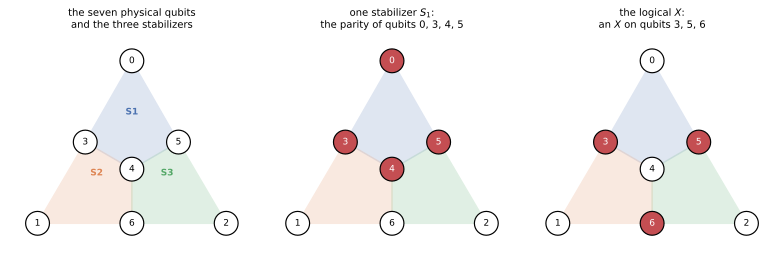

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
draw_code(title="the seven physical qubits\nand the three stabilizers", ax=axes[0])
draw_code(highlight=GENS[0], title="one stabilizer $S_1$:\nthe parity of qubits 0, 3, 4, 5", label_faces=False, ax=axes[1])
draw_code(highlight=LOGICAL_X, title="the logical $X$:\nan $X$ on qubits 3, 5, 6", label_faces=False, ax=axes[2])
plt.tight_layout(); plt.show()

## 2. The encoder, and which gates are transversal

To put a qubit into the code we run an **encoder**: a small circuit of Hadamards and CNOTs that takes $|\psi\rangle$ on one qubit, six qubits in $|0\rangle$, and spreads the state over all seven.

Nothing below is taken on trust. The cell computes the encoder's matrix and asks the computer which Pauli operators leave the encoded states alone (those are the stabilizers) and which act as logical $X$ and $Z$.

In [4]:
def encoder_circuit(n=7):
    c = Circuit(n)
    for g in encoder_gates(list(range(7))):
        c.add_gate(g)
    return c

def isometry(circuit, input_qubit=IN_QUBIT, n=7):
    '''The map |psi> -> circuit(|psi> on input_qubit, |0> elsewhere), as a 2^n x 2 matrix.'''
    U = circuit.to_matrix()
    v0, v1 = np.zeros(2 ** n, complex), np.zeros(2 ** n, complex)
    v0[0] = 1
    v1[1 << (n - 1 - input_qubit)] = 1
    E = np.stack([U @ v0, U @ v1], axis=1)
    return E / np.linalg.norm(E[:, 0])

def pauli(kind, support, n=7):
    m = {'X': np.array([[0, 1], [1, 0]], complex), 'Z': np.diag([1, -1]).astype(complex)}[kind]
    out = np.array([[1]], complex)
    for q in range(n):
        out = np.kron(out, m if q in support else np.eye(2))
    return out

E = isometry(encoder_circuit())
print("the encoder is an isometry:", np.allclose(E.conj().T @ E, np.eye(2)))
stabilizers = {kind: [s for k in (4,) for s in itertools.combinations(range(7), k)
                      if np.allclose(pauli(kind, s) @ E, E)] for kind in ('X', 'Z')}
print("weight-4 X stabilizers:", stabilizers['X'])
print("weight-4 Z stabilizers:", stabilizers['Z'], " (self-dual: the same supports)")
X1, Z1 = np.array([[0, 1], [1, 0]], complex), np.diag([1, -1]).astype(complex)
print("logical X = X^7:", np.allclose(pauli('X', range(7)) @ E, E @ X1),
      "   logical Z = Z^7:", np.allclose(pauli('Z', range(7)) @ E, E @ Z1))

the encoder is an isometry: True
weight-4 X stabilizers: [(0, 1, 2, 4), (0, 1, 5, 6), (0, 2, 3, 6), (0, 3, 4, 5), (1, 2, 3, 5), (1, 3, 4, 6), (2, 4, 5, 6)]
weight-4 Z stabilizers: [(0, 1, 2, 4), (0, 1, 5, 6), (0, 2, 3, 6), (0, 3, 4, 5), (1, 2, 3, 5), (1, 3, 4, 6), (2, 4, 5, 6)]  (self-dual: the same supports)
logical X = X^7: True    logical Z = Z^7: True


Seven four-qubit stabilizers of each type, on the same supports, with $X_L = X^{\otimes 7}$ and $Z_L = Z^{\otimes 7}$: that is the Steane code, derived rather than asserted.

Now the transversal gates. "Apply $U$ to each of the seven qubits and see what happens to the logical qubit" is the matrix $E^\dagger U^{\otimes 7} E$, where $E$ is the encoder:

In [5]:
def logical_action(U, iso=E):
    return iso.conj().T @ U @ iso

def equal_up_to_phase(A, B):
    for a, b in zip(np.asarray(A).flatten(), np.asarray(B).flatten()):
        if abs(b) > 1e-9:
            return bool(np.allclose(A, (a / b) * B))
    return False

def transversal(gate, n=7):
    c = Circuit(n)
    for q in range(n):
        c.add_gate(gate(q))
    return c.to_matrix()

H1 = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
S1 = np.diag([1, 1j]).astype(complex)
print("H on all seven qubits  -> logical H      :", equal_up_to_phase(logical_action(transversal(HAD)), H1))
print("S on all seven qubits  -> logical S-dagger:", equal_up_to_phase(logical_action(transversal(S)), S1.conj()))
print("   (so the logical S we need for the correction is S-dagger on all seven qubits)")

# transversal CNOT on two blocks: a permutation of basis states, so no 2^14 x 2^14 matrix is needed
EE = np.kron(E, E)                                   # encoded two-qubit basis, 2^14 x 4
perm = [((a >> 7) << 7) | (((a >> 7) ^ a) & 0x7F) for a in range(2 ** 14)]   # |a>|b> -> |a>|a+b>
print("CNOT on all seven pairs -> logical CNOT  :",
      equal_up_to_phase(EE.conj().T @ EE[perm, :], np.eye(4)[[0, 1, 3, 2]]))

H on all seven qubits  -> logical H      : True
S on all seven qubits  -> logical S-dagger: True
   (so the logical S we need for the correction is S-dagger on all seven qubits)
CNOT on all seven pairs -> logical CNOT  : True


So $H$ on every qubit is a logical $H$, $S$ on every qubit is a logical $S^\dagger$ (so the logical $S$ we need later is $S^\dagger$ applied seven times), and a CNOT between the two blocks, qubit by qubit, is a logical CNOT.

**But there is no line for $T$** — and that is the point. $T$ applied to all seven qubits does *not* give a logical $T$; it takes the state out of the code space entirely. That is why the protocol below exists.

## 3. The trick: injection

Instead of applying $T$ directly, we use a gadget that needs only gates from the transversal list, plus one special state prepared in advance:

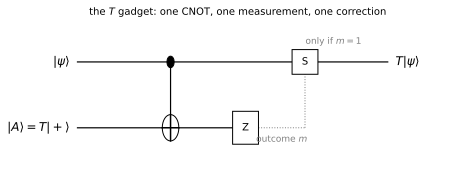

In [6]:
draw_gadget(); plt.show()

Read it left to right. The data qubit $|\psi\rangle$ is the one we want to apply $T$ to. The second qubit starts in the magic state $|A\rangle = T|+\rangle$, which is prepared once, independently of the data. A CNOT couples them, the second qubit is measured, and the measurement destroys it while leaving the data qubit in $T|\psi\rangle$ — *if* the outcome was 0. If the outcome was 1, the data qubit is in $S^\dagger T|\psi\rangle$ instead and a correction $S$ puts it right. The outcome is random, so both cases happen in practice.

Everything in that gadget — CNOT, $Z$ measurement, $S$ — is transversal in the Steane code. So the *logical* version of the gadget is: a logical magic state in a second code block, seven CNOTs, seven measurements, and (if needed) $S^\dagger$ on all seven data qubits.

## 4. The protocol as a program

Twenty qubits: the data block `0..6`, a second block `7..13` that will hold the magic state, and six ancillas `14..19` used to measure the stabilizers once, as a check that the magic state was encoded correctly.

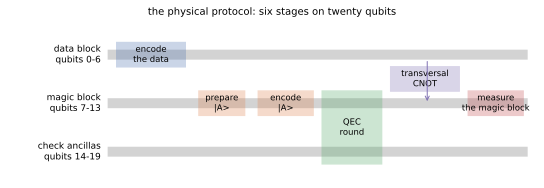

In [7]:
draw_protocol(); plt.show()

Each box is a **stage** of a `QProgram`. The logical input is an open wire on qubit 3 — everything else starts in $|0\rangle$ — so the program is a map from one logical qubit to the encoded output, with the measurement outcomes left as symbols.

In [8]:
DATA, MAGIC, ANC = list(range(7)), list(range(7, 14)), list(range(14, 20))
N, BITS = 20, 16

def stage(gates):
    c = Circuit(N, bit_amount=BITS)
    for g in gates:
        c.add_gate(g)
    return c

p = QProgram(N, bits=BITS,
             initial_states={q: '0' for q in DATA + MAGIC + ANC if q != IN_QUBIT})
p.add_circuit(stage(encoder_gates(DATA)), name="encode the data block")
p.add_circuit(stage([HAD(MAGIC[IN_QUBIT]), T(MAGIC[IN_QUBIT])]), name="prepare |A> = T|+>")
p.add_circuit(stage(encoder_gates(MAGIC)), name="encode |A>")

checks = []
for k, support in enumerate(GENS):                           # X checks: ancilla in |+>, CNOT ancilla -> data
    a = ANC[k]
    checks += [HAD(a)] + [CNOT(a, MAGIC[q]) for q in support] + [HAD(a), Measurement(a, k)]
for k, support in enumerate(GENS):                           # Z checks: CNOT data -> ancilla
    a = ANC[3 + k]
    checks += [CNOT(MAGIC[q], a) for q in support] + [Measurement(a, 3 + k)]
p.add_circuit(stage(checks), name="QEC round on the magic block")

p.add_circuit(stage([CNOT(DATA[q], MAGIC[q]) for q in range(7)]), name="transversal CNOT")
p.add_circuit(stage([Measurement(MAGIC[q], 6 + q) for q in range(7)]), name="transversal measurement")

g = p.quantum_graph()
print(sum(1 for v in g.vertices() if g.type(v) != VertexType.BOUNDARY), "spiders;",
      "input", g.inputs(), " outputs", len(g.outputs()), " outcomes", len(boolean_variables(g)))
print(p.describe_level(0))

165 spiders; input (3,)  outputs 7  outcomes 13
Level 0 (6 blocks):
  Block 0 'encode the data block': [encode the data block]
  Block 1 'prepare |A> = T|+>': [prepare |A> = T|+>]
  Block 2 'encode |A>': [encode |A>]
  Block 3 'QEC round on the magic block': [QEC round on the magic block]
  Block 4 'transversal CNOT': [transversal CNOT]
  Block 5 'transversal measurement': [transversal measurement]


165 spiders, one input, seven outputs, thirteen measurement outcomes. Here is the whole thing as a ZX-diagram on a time axis, one shade per stage (drag the spiders, scroll to zoom):

In [9]:
draw_program_web(p, level=0, vdata=())

## 5. Levelling up

The stages above are *physical* steps. Level-up groups them into the **logical** operations they implement: everything that prepares the logical magic state becomes one block, the seven CNOTs become "logical CNOT", the seven measurements become "logical measurement".

In [10]:
lvl1 = p.level_up(0, 1, 3, name="prepare the logical magic state")
print(p.describe_level(lvl1))
lvl2 = p.level_up(lvl1, 0, 3, name="logical T injection")
print(p.describe_level(lvl2))

Level 1 (4 blocks):
  Block 0 'encode the data block': [encode the data block]
  Block 1 'prepare the logical magic state': [prepare |A> = T|+>, encode |A>, QEC round on the magic block]
  Block 2 'transversal CNOT': [transversal CNOT]
  Block 3 'transversal measurement': [transversal measurement]
Level 2 (1 blocks):
  Block 0 'logical T injection': [encode the data block, prepare |A> = T|+>, encode |A>, QEC round on the magic block, transversal CNOT, transversal measurement]


Grouping changes what the measurements mean, and that is the real reason to do it. Take the QEC round. On its own, the block sees an arbitrary input state, so its six check outcomes could be anything. Merged with the encoder that comes before it, the input is a perfect code state, so every check must return 0 — and the reduction proves it:

In [11]:
prep = p.measurement_report(lvl1, 1)          # the "prepare the logical magic state" block, in context
print(prep.summary())
print(prep.table())
print("\nthe same block in isolation:", p.measurement_report(lvl1, 1, context=False).summary().splitlines()[1])

6 measurements in block 1 of level 1 (prepare the logical magic state); Pauli frame: Z(c[7] + c[9] + c[6])
6 fixed
6 detectors (6 of them internal); outcome space of the diagram: 9 forced + 1 steering the map + 3 gauge = 13


outcome  stage  qubit  pos  t   fate   why
c[0]     3      14     14   24  fixed  always 0: nothing in the protocol can change it
c[1]     3      15     15   25  fixed  always 0: nothing in the protocol can change it
c[3]     3      17     17   26  fixed  always 0: nothing in the protocol can change it
c[2]     3      16     16   27  fixed  always 0: nothing in the protocol can change it
c[4]     3      18     18   27  fixed  always 0: nothing in the protocol can change it
c[5]     3      19     19   29  fixed  always 0: nothing in the protocol can change it

the same block in isolation: 6 frame


Read the table as: *for each measurement, what happens to it when the protocol runs without errors*. `fixed: always 0` means the outcome is deterministic — so if the hardware ever returns 1 there, something went wrong. These six are the protocol's error-detection handles, and the last line shows they exist only thanks to the level-up: the same block alone has none.

The final round is different. Seven qubits are measured one by one, and the code makes three parities of those seven outcomes deterministic — they are the stabilizers again, now reconstructed from the readout instead of measured with an ancilla:

In [12]:
meas = p.measurement_report(lvl1, 3)          # the "transversal measurement" block, in context
print(meas.summary())
print(meas.table())

7 measurements in block 3 of level 1 (transversal measurement); Pauli frame: Z(c[7] + c[9] + c[6])
3 frame; 4 tied
3 detectors (3 of them internal); outcome space of the diagram: 9 forced + 1 steering the map + 3 gauge = 13
outcome  stage  qubit  pos  t   fate   why
c[6]     5      7      7    31  frame  the map depends on it: Z correction, with c[7], c[9]
c[7]     5      8      8    31  frame  the map depends on it: Z correction, with c[6], c[9]
c[8]     5      9      9    31  tied   its parity with c[10] (stage 5, qubit 11, t=31), c[6] (stage 5, qubit 7, t=31), c[7] (stage 5, qubit 8, t=31) is deterministic (c[10] + c[8] + c[7] + c[6] = 0)
c[9]     5      10     10   31  frame  the map depends on it: Z correction, with c[6], c[7]
c[10]    5      11     11   31  tied   its parity with c[6] (stage 5, qubit 7, t=31), c[7] (stage 5, qubit 8, t=31), c[8] (stage 5, qubit 9, t=31) is deterministic (c[10] + c[8] + c[7] + c[6] = 0)
c[11]    5      12     12   31  tied   its parity with c[7] (

Three of the seven outcomes are marked `frame`: the logical result depends on them, and that is what the correction will use. Four are `tied`: their value is random, but a parity involving them is fixed, so they carry no new information about the logical qubit.

The frame reads `Z(c[6] + c[7] + c[9])`, which *is* the parity of all seven readouts once the three deterministic parities are substituted into it — the reduction just prefers a shorter representative. Two diagrams should always be compared modulo those relations, never symbol by symbol.

## 6. What the protocol actually implements

Reducing the whole program, with the outcomes kept symbolic, gives the **detectors**: every parity of outcomes that is deterministic in an error-free run — the six checks and the three stabilizer parities.

In [13]:
res = reduce_gpf(g)
print(f"{len(res.detectors)} detectors:")
for d in res.detectors:
    print("   ", d, "= 0")
print("\nzero diagram:", res.is_zero, " reduced diagram:", res.graph.num_vertices(), "vertices")

9 detectors:
    c[0] = 0
    c[1] = 0
    c[2] = 0
    c[3] = 0
    c[4] = 0
    c[5] = 0
    c[10] + c[8] + c[7] + c[6] = 0
    c[11] + c[7] + c[9] + c[8] = 0
    c[12] + c[9] + c[6] + c[8] = 0

zero diagram: False  reduced diagram: 21 vertices


And this is what is left of the protocol. The 165 spiders have collapsed to a handful: one Z spider and one X spider whose phases are the corrections, and a Hadamard-free wire per output. Everything else went into the detectors above.

In [14]:
zx.draw(res.to_graph(), labels=True)

And the logical answer. For an outcome that can occur, the reduced diagram is compared with the code space: $M = E^\dagger \cdot (\text{reduced map})$ is the gate seen by the logical qubit, and `in the code space` confirms the protocol did not leave the code.

In [15]:
T1 = np.diag([1, np.exp(1j * np.pi / 4)])
CANDIDATES = {'T': T1, 'S T': S1 @ T1, 'S-dagger T': S1.conj() @ T1,
              'Z T': Z1 @ T1, 'S Z T': S1 @ Z1 @ T1, 'S-dagger Z T': S1.conj() @ Z1 @ T1}

def identify(M):
    return next((name for name, ref in CANDIDATES.items() if equal_up_to_phase(M, ref)), "not in the list")

names = boolean_variables(g)
readout = ['c[{}]'.format(6 + q) for q in range(7)]
rng = random.Random(1)
print(f"{'readout':10} {'logical Z readout':18} {'logical operator':16} in the code space")
for _ in range(8):
    a = sample_consistent_assignment(res.constraints, names, rng)
    t = res.to_graph().substitute_variables(a).to_tensor(preserve_scalar=False).reshape(128, 2)
    t = t / np.linalg.norm(t[:, 0])
    M = E.conj().T @ t
    print(f"   {''.join(str(a[r]) for r in readout):10} {sum(a[r] for r in readout) % 2:^18} "
          f"{identify(M):16} {np.allclose(E @ M, t)}")

readout    logical Z readout  logical operator in the code space
   0101101            0          T                True
   0010111            0          T                True
   1101000            1          S-dagger T       True
   1101000            1          S-dagger T       True
   0111010            0          T                True
   0011100            1          S-dagger T       True
   1101000            1          S-dagger T       True
   0001011            1          S-dagger T       True


That is the verification, in one table:

* when the logical readout is **0** the protocol applies exactly $T$ — the gate we wanted;
* when it is **1** it applies $S^\dagger T$, and §2 told us the fix: a logical $S$, i.e. $S^\dagger$ on all seven qubits;
* the individual readouts never matter, only their parity, so the "gauge" outcomes the report identified really are irrelevant;
* every branch stays in the code space, so the logical qubit is still protected afterwards.

## 7. The one thing that does not fit yet

The correction is *conditional*: apply $S_L$ only when the readout is 1. Conditional **Pauli** corrections are fine here — a Pauli conditioned on an outcome $c$ is just a phase $\pi c$ on a spider, and the whole machinery is built to carry those symbolically. A conditional $S$ is not: it would need the phase $\tfrac{\pi}{2}(c_6 \oplus \dots \oplus c_{12})$, and $\oplus$ is not linear in phase arithmetic — two outcomes equal to 1 would give $\pi$ where the truth is $0$.

So the two branches are verified separately, as in the table above. Supporting it properly means letting a block carry a Clifford that depends on the outcomes, which is the next piece of work on the library.